# Tarea 2 · Deep Learning (CIT3360) — Ítem 2: Faster R-CNN con transfer learning

Detector **Faster R-CNN ResNet50-FPN v2** (torchvision) inicializado con **pesos preentrenados en COCO** y ajustado a FjordFish con *fine-tuning* completo. Usa los mismos datos que la CNN propia: las mismas particiones y el mismo código de letterbox y aumento de datos, con las mismas semillas.

**Ítems de la rúbrica**
- 2.1 (Faster R-CNN con pesos COCO): secciones 4 a 8.
- 2.2 (qué se congeló, qué se entrenó y si hubo *fine-tuning*): sección 4.
- 2.3 (justificación de hiperparámetros, épocas y aumento de datos): sección 12.
- 2.4 (comparación con los modelos desde cero): `05_comparacion.ipynb`, con los archivos que deja la sección 11.

**Decisiones del grupo que usa este cuaderno** (`PLAN_TAREA2.md` §4)
- Entrada de 640 px con *letterbox* (D3), el mismo aumento de datos en los cuatro modelos, sin mosaico (D5), y las 28 categorías de `data.yaml` (D6).
- *Fine-tuning* completo con ResNet50-FPN v2, lote de 4 y SGD con tasa de aprendizaje 0,005 (D7).
- Hasta 100 épocas, paciencia 25 y parada por mAP50-95 de validación, los mismos valores de la CNN propia.

**Contenido**
0. Entorno · 1. Configuración · 2. Verificación de las particiones · 3. Datos: letterbox y aumento · 4. Arquitectura, pesos COCO y congelamiento · 5. Optimizador y ciclo de entrenamiento · 6. Entrenamiento · 7. Curvas · 8. Evaluación en validación y test · 9. Eficiencia · 10. Resultados cualitativos · 11. Predicciones y resumen para la comparación · 12–13. Justificación y análisis (grupo) · Declaración de uso de IA

## 0. Entorno

Requiere PyTorch con CUDA, torchvision y OpenCV (ver `requirements.txt`) y `comun.py` en la misma carpeta. La primera vez, torchvision descarga los pesos COCO del modelo.

In [1]:
from collections import Counter
import gc
import json
import logging
import math
import os
import random
import time
import platform
import warnings
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")   # cuBLAS determinista, como YOLO; debe ir antes de usar CUDA
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import torch
import torch.nn as nn
import yaml
from PIL import Image
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

logging.getLogger("torch.utils.flop_counter").setLevel(logging.ERROR)   # oculta un aviso sobre triton que aquí no aplica
from torch.utils.flop_counter import FlopCounterMode

from comun import (cargar_particiones, verificar_huella, leer_etiquetas_yolo, cargar_cajas_reales, evaluar_detecciones,
                   COLUMNAS_PREDICCIONES, CARPETA_RUNS)

warnings.filterwarnings("ignore", message=".*does not have a deterministic implementation.*")   # ver la sección 5

print("Python  :", platform.python_version())
print("PyTorch :", torch.__version__, "| CUDA disponible:", torch.cuda.is_available())
print("OpenCV  :", cv2.__version__)
if torch.cuda.is_available():
    print("GPU     :", torch.cuda.get_device_name(0))
DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cv2.setNumThreads(1)   # la carga en paralelo la hacen los hilos de `lotes`; así OpenCV no compite con ellos

Python  : 3.14.0
PyTorch : 2.14.0+cu130 | CUDA disponible: True
OpenCV  : 5.0.0
GPU     : NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
# Estilo de los gráficos: colores categóricos en orden fijo (azul, naranja, aqua) y ejes discretos
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False, "figure.dpi": 100,
})

## 1. Configuración

Los parámetros del experimento están en esta celda.

| Parámetro | Qué controla |
|---|---|
| `PRUEBA_RAPIDA`, `ENTRENAR` | prueba rápida; entrenar o reutilizar el entrenamiento guardado |
| `LADO` | lado de la imagen de entrada en px (D3) |
| `CAPAS_ENTRENABLES_BACKBONE` | capas del backbone que se entrenan: 5 = todas, *fine-tuning* completo (D7) |
| `EPOCAS`, `PACIENCIA` | máximo de épocas y parada temprana por mAP50-95 de validación |
| `LOTE`, `TASA_APRENDIZAJE`, `MOMENTUM`, `WEIGHT_DECAY` | tamaño de lote y SGD con tasa constante (D7) |
| `PRECISION_MIXTA` | float16 en la GPU para entrenar y para la validación de cada época; la evaluación final y la velocidad se miden en float32, como en los otros modelos |
| `HILOS_CARGA`, `LOTE_EVALUACION`, `LOTE_VELOCIDAD` | hilos que preparan las imágenes, imágenes por paso al evaluar (no cambia los resultados) y lote de la medición de velocidad |
| `ESCALA`, `TRASLACION`, `HSV_H`, `HSV_S`, `HSV_V`, `VOLTEO`, `COLOR_RELLENO` | aumento de datos y letterbox: los mismos valores de los cuatro modelos (D5) |
| `CONF_EVALUACION`, `IOU_NMS`, `MAX_DETECCIONES` | detecciones que se guardan para el mAP, con los mismos valores de los otros modelos |
| `UMBRAL_CONFIANZA` | confianza mínima de las detecciones que se dibujan, de la precisión y el recall de este cuaderno y de la medición de velocidad (provisorio hasta que el grupo fije el umbral común, D8) |
| `N_IMAGENES_VELOCIDAD`, `N_CALENTAMIENTO`, `N_LOTES_VELOCIDAD`, `N_EJEMPLOS` | imágenes para medir la velocidad, imágenes de calentamiento antes de medir, lotes de la medición en lote e imágenes de los ejemplos cualitativos |

Con `PRUEBA_RAPIDA = True` el cuaderno corre en unos minutos (2 épocas con el 5 % de train) y escribe en `pruebas/`, sin pisar los resultados reales. Con `ENTRENAR = False` se reutiliza el entrenamiento guardado.

Los pesos y registros del entrenamiento se guardan en `~/tarea2_runs/` (`CARPETA_RUNS` de `comun.py`), fuera de OneDrive. Las tablas y figuras van en `resultados/faster_rcnn/`.

In [3]:
RAIZ = Path.cwd()
PRUEBA_RAPIDA = False       # True: pocas imágenes y épocas para probar el flujo completo en minutos
ENTRENAR = False            # False: reutiliza el entrenamiento guardado en DIR_RUNS

DIR_DATASET = RAIZ / "datasets" / "fjordfish"
DIR_SPLITS = RAIZ / "splits"
DIR_BASE = RAIZ / "pruebas" if PRUEBA_RAPIDA else RAIZ      # las pruebas no pisan los resultados reales
DIR_RUNS = CARPETA_RUNS / ("pruebas" if PRUEBA_RAPIDA else "reales") / "faster_rcnn"   # pesos y registros, fuera de OneDrive
DIR_RESULTADOS = DIR_BASE / "resultados" / "faster_rcnn"     # tablas y figuras para la presentación
SEMILLA = 42

# Modelo (D3, D6 y D7)
LADO = 640                         # entrada de LADO × LADO px con letterbox
NUM_CLASES = 28                    # clases 0..27 de data.yaml; torchvision agrega el fondo en el índice 0
CAPAS_ENTRENABLES_BACKBONE = 5     # 5 = todas las capas del backbone: fine-tuning completo

# Entrenamiento
EPOCAS = 100                       # los mismos valores de la CNN propia
PACIENCIA = 25                     # épocas sin mejorar el mAP50-95 de validación
LOTE = 4                           # D7
TASA_APRENDIZAJE = 0.005           # D7, constante durante todo el entrenamiento
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4                # regularización L2
PRECISION_MIXTA = True             # float16 en la GPU, como los otros modelos
USAR_AMP = PRECISION_MIXTA and DISPOSITIVO.type == "cuda"
HILOS_CARGA = 8                    # hilos que leen y aumentan imágenes en paralelo
LOTE_EVALUACION = 4                # imágenes por paso al evaluar (no cambia los resultados)
LOTE_VELOCIDAD = 8                 # medido en la RTX 4060 de 8 GB: 63 ms por imagen; con 16 se desborda la memoria (574 ms)

# Aumento de datos y letterbox: los mismos valores de los cuatro modelos, sin mosaico (D5)
ESCALA = 0.5                       # factor de escala al azar en [1 − ESCALA, 1 + ESCALA]
TRASLACION = 0.1                   # desplazamiento al azar del centro: hasta ±10 % del lado
HSV_H, HSV_S, HSV_V = 0.015, 0.7, 0.4    # variación máxima de tono, saturación y brillo
VOLTEO = 0.5                       # probabilidad de volteo horizontal
COLOR_RELLENO = 114                # gris del letterbox

# Evaluación (los mismos valores de los otros modelos)
CONF_EVALUACION = 0.001            # confianza mínima de las detecciones que se guardan para el mAP
IOU_NMS = 0.7
MAX_DETECCIONES = 300              # por imagen (el mismo límite que aplica comun.py)
UMBRAL_CONFIANZA = 0.25            # provisorio: el grupo fija el umbral común con validación (D8)
N_IMAGENES_VELOCIDAD = 200
N_CALENTAMIENTO = 10               # imágenes que se procesan antes de empezar a medir
N_LOTES_VELOCIDAD = 5              # lotes de LOTE_VELOCIDAD imágenes en la medición en lote
N_EJEMPLOS = 4

FRACCION_TRAIN = 1.0               # parte de train que se usa (solo se reduce en la prueba rápida)
if PRUEBA_RAPIDA:
    EPOCAS = 2
    PACIENCIA = 2
    FRACCION_TRAIN = 0.05

random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
DIR_RUNS.mkdir(parents=True, exist_ok=True)
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)
print(f"Lote de {LOTE} imágenes | SGD con lr {TASA_APRENDIZAJE} | hasta {EPOCAS} épocas con paciencia {PACIENCIA}")

Lote de 4 imágenes | SGD con lr 0.005 | hasta 100 épocas con paciencia 25


Funciones para dibujar que se usan en varias secciones: un lienzo de la red con sus cajas normalizadas, una imagen con cajas en píxeles (reales o predichas) y un eje de épocas con números enteros.

In [4]:
def dibujar_lienzo(ax, imagen, objetivos, titulo):
    """Muestra un lienzo de LADO × LADO con sus cajas (objetivos normalizados: clase, cx, cy, w, h)."""
    ax.imshow(imagen.permute(1, 2, 0).numpy())
    for _, cx, cy, w, h in objetivos.tolist():
        ax.add_patch(plt.Rectangle(((cx - w / 2) * LADO, (cy - h / 2) * LADO), w * LADO, h * LADO,
                                   fill=False, ec=NARANJA, lw=1.5))
    ax.set_title(titulo, fontsize=9)
    ax.axis("off")


def dibujar_cajas(ax, img, cajas, titulo):
    """Muestra una imagen con sus cajas en píxeles (tabla con clase_id, x1, y1, x2, y2 y, si la hay, confianza)."""
    ax.imshow(img)
    for fila in cajas.itertuples():
        ax.add_patch(plt.Rectangle((fila.x1, fila.y1), fila.x2 - fila.x1, fila.y2 - fila.y1,
                                   fill=False, ec=NARANJA, lw=1.5))
        texto = NOMBRES[fila.clase_id] + (f" {fila.confianza:.2f}" if hasattr(fila, "confianza") else "")
        ax.text(fila.x1, fila.y1, texto, color="white", fontsize=7, va="top" if fila.y1 < 0.05 * img.height else "bottom",
                bbox=dict(fc=NARANJA, ec="none", pad=1), clip_on=True)
    ax.set_title(titulo, fontsize=9)
    ax.axis("off")


def epocas_enteras(ax):
    """Deja solo números enteros en el eje de las épocas."""
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

## 2. Verificación del dataset y de las particiones

Se comprueba que las carpetas del dataset coinciden con `splits/*.txt` y que la **huella** de las particiones es la común del grupo (`7d4e588f7cc4`). Si no coincide, el cuaderno se detiene: así se garantiza que los cuatro modelos usan las mismas particiones.

In [5]:
assert (DIR_DATASET / "fjordfish.yaml").exists(), "Primero hay que ejecutar 00_preparacion_dataset.ipynb"
datos = yaml.safe_load((DIR_DATASET / "fjordfish.yaml").read_text(encoding="utf-8"))
NOMBRES = datos["names"]
assert len(NOMBRES) == NUM_CLASES, "NUM_CLASES no coincide con data.yaml"
particion, huella = cargar_particiones(DIR_SPLITS)
verificar_huella(huella)

filas = []
for s, ids in particion.items():
    en_disco = {p.stem for p in (DIR_DATASET / "images" / s).glob("*.jpg")}
    assert en_disco == set(ids), f"images/{s} no coincide con splits/{s}.txt"
    n_cajas = sum(len(leer_etiquetas_yolo(DIR_DATASET / "labels" / s / f"{i}.txt")) for i in ids)
    filas.append({"partición": s, "imágenes": len(ids), "cajas": n_cajas})
print(f"{NUM_CLASES} clases | huella de la partición: {huella} (verificada)")
pd.DataFrame(filas).set_index("partición")

28 clases | huella de la partición: 7d4e588f7cc4 (verificada)


,imágenes,cajas
partición,,
train,1773,3717
val,313,667
test,916,1963


## 3. Datos: letterbox y aumento de datos

Este cuaderno usa **exactamente el mismo código de datos que la CNN propia** (`01_cnn_propia_desde_cero.ipynb`, sección 3), y ese código aplica el mismo aumento que YOLO:
1. La imagen se cambia de tamaño para que su lado mayor mida `LADO` px, sin deformarla.
2. Se ubica en un lienzo gris de `LADO` × `LADO` (*letterbox*). En entrenamiento, además, se escala al azar entre 0,5× y 1,5× y su centro se desplaza hasta ±10 %; se descartan las cajas que quedan con menos del 10 % de su área o con un lado de 2 px o menos.
3. Solo en entrenamiento: cambios de tono, saturación y brillo (HSV) y volteo horizontal con probabilidad 0,5.

La semilla del aumento depende de la imagen y de la época, así que en cada época Faster R-CNN recibe exactamente las mismas variantes de cada imagen que recibió la CNN propia. YOLO aplica las mismas transformaciones con la misma distribución, pero con sus propios sorteos.

Las imágenes se preparan en varios hilos en paralelo. Se usan hilos y no el `DataLoader` de PyTorch con procesos porque en Windows esos procesos no pueden usar clases definidas dentro de un cuaderno.

In [6]:
def cxcywh_a_xyxy(cajas):
    """Cajas (cx, cy, w, h) → (x1, y1, x2, y2), en las mismas unidades."""
    cx, cy, w, h = np.asarray(cajas, dtype=np.float64).reshape(-1, 4).T
    return np.stack([cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], axis=1)


def xyxy_a_cxcywh(cajas):
    """Cajas (x1, y1, x2, y2) → (cx, cy, w, h), en las mismas unidades."""
    x1, y1, x2, y2 = np.asarray(cajas, dtype=np.float64).reshape(-1, 4).T
    return np.stack([(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1], axis=1)


def redimensionar(img):
    """Cambia el tamaño de la imagen para que su lado mayor mida LADO px, sin deformarla (como Ultralytics)."""
    alto, ancho = img.shape[:2]
    r = LADO / max(alto, ancho)
    tamano = (min(math.ceil(ancho * r), LADO), min(math.ceil(alto * r), LADO))
    return cv2.resize(img, tamano, interpolation=cv2.INTER_LINEAR)


def ubicar_en_lienzo(img, cajas, rng=None):
    """Letterbox: ubica la imagen en un lienzo gris de LADO × LADO; con `rng`, además la escala y la desplaza al azar."""
    # Devuelve el lienzo, las cajas que se conservan (px del lienzo), cuáles se conservan y (escala, dx, dy)
    alto, ancho = img.shape[:2]
    escala, centro_x, centro_y = 1.0, LADO / 2, LADO / 2
    if rng is not None:
        escala = rng.uniform(1 - ESCALA, 1 + ESCALA)
        centro_x, centro_y = rng.uniform(0.5 - TRASLACION, 0.5 + TRASLACION, size=2) * LADO
    dx, dy = centro_x - escala * ancho / 2, centro_y - escala * alto / 2   # la imagen queda centrada en (centro_x, centro_y)
    if rng is None:   # letterbox centrado con desplazamiento entero, como Ultralytics (sin interpolar medio píxel)
        dx, dy = round(dx - 0.1), round(dy - 0.1)
    matriz = np.array([[escala, 0, dx], [0, escala, dy]], dtype=np.float32)
    lienzo = cv2.warpAffine(img, matriz, (LADO, LADO), borderValue=(COLOR_RELLENO,) * 3)
    nuevas = (cajas * escala + [dx, dy, dx, dy]).clip(0, LADO)
    conservar = np.ones(len(cajas), dtype=bool)
    if rng is not None:   # mismo criterio que Ultralytics: lado > 2 px, al menos 10 % del área y proporción < 100
        ancho_antes, alto_antes = (cajas[:, 2] - cajas[:, 0]) * escala, (cajas[:, 3] - cajas[:, 1]) * escala
        ancho_ahora, alto_ahora = nuevas[:, 2] - nuevas[:, 0], nuevas[:, 3] - nuevas[:, 1]
        proporcion = np.maximum(ancho_ahora / (alto_ahora + 1e-16), alto_ahora / (ancho_ahora + 1e-16))
        conservar = ((ancho_ahora > 2) & (alto_ahora > 2) & (proporcion < 100)
                     & (ancho_ahora * alto_ahora / (ancho_antes * alto_antes + 1e-16) > 0.1))
    return lienzo, nuevas[conservar], conservar, (escala, dx, dy)


def variar_hsv(img, rng):
    """Cambia al azar el tono, la saturación y el brillo con las mismas tablas que Ultralytics (RandomHSV)."""
    r = rng.uniform(-1, 1, size=3) * [HSV_H, HSV_S, HSV_V]
    x = np.arange(256, dtype=np.float64)
    tono = ((x + r[0] * 180) % 180).astype(np.uint8)              # en OpenCV el tono va de 0 a 179
    saturacion = np.clip(x * (r[1] + 1), 0, 255).astype(np.uint8)
    brillo = np.clip(x * (r[2] + 1), 0, 255).astype(np.uint8)
    saturacion[0] = 0                                             # como Ultralytics: un gris o un blanco sigue sin color
    tabla = np.stack((tono, saturacion, brillo), axis=-1).reshape(1, 256, 3)
    return cv2.cvtColor(cv2.LUT(cv2.cvtColor(img, cv2.COLOR_BGR2HSV), tabla), cv2.COLOR_HSV2BGR)

El `Dataset` aplica esos pasos a cada imagen y entrega la imagen, sus cajas y los datos para deshacer el letterbox.

In [7]:
class DatasetFjordFish(torch.utils.data.Dataset):
    """Imágenes y cajas de una partición, preparadas como en YOLO: letterbox y, si `aumentar`, aumento de datos."""

    def __init__(self, split, ids, aumentar):
        self.split, self.ids, self.aumentar = split, list(ids), aumentar
        self.epoca = 0                  # forma parte de la semilla del aumento: cada época ve variantes nuevas

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        """Devuelve la imagen (3 × LADO × LADO, uint8, RGB), sus objetivos (n, 5) y los datos para deshacer el letterbox."""
        id_img = self.ids[i]
        original = cv2.imread(str(DIR_DATASET / "images" / self.split / f"{id_img}.jpg"))     # BGR
        img = redimensionar(original)
        alto, ancho = img.shape[:2]
        etiquetas = leer_etiquetas_yolo(DIR_DATASET / "labels" / self.split / f"{id_img}.txt")
        cajas = cxcywh_a_xyxy(etiquetas[:, 1:]) * [ancho, alto, ancho, alto]
        rng = np.random.default_rng([SEMILLA, self.epoca, i]) if self.aumentar else None
        lienzo, cajas, conservar, (escala, dx, dy) = ubicar_en_lienzo(img, cajas, rng)
        clases = etiquetas[conservar, 0]
        if self.aumentar:
            lienzo = variar_hsv(lienzo, rng)
            if rng.random() < VOLTEO:
                lienzo = lienzo[:, ::-1]
                cajas[:, [0, 2]] = LADO - cajas[:, [2, 0]]          # al voltear, x1 nuevo = LADO − x2 y x2 nuevo = LADO − x1
        imagen = torch.from_numpy(np.ascontiguousarray(lienzo[..., ::-1].transpose(2, 0, 1)))   # BGR → RGB
        objetivos = torch.from_numpy(np.column_stack([clases, xyxy_a_cxcywh(cajas) / LADO]).astype(np.float32))
        # Para volver a px de la imagen original: x = (x_lienzo − dx) · factor_x  (y lo mismo en y)
        datos_letterbox = {"id": id_img, "ancho": original.shape[1], "alto": original.shape[0], "dx": dx, "dy": dy,
                           "factor_x": original.shape[1] / (ancho * escala), "factor_y": original.shape[0] / (alto * escala)}
        return imagen, objetivos, datos_letterbox

`lotes` recorre un dataset por lotes: las imágenes de cada lote se preparan en `HILOS_CARGA` hilos (OpenCV libera el GIL, así que trabajan en paralelo) y el lote siguiente se va preparando mientras la GPU procesa el actual.

In [8]:
def juntar(muestras):
    """Arma un lote: imágenes (B, 3, LADO, LADO), lista de objetivos por imagen y lista de datos del letterbox."""
    imagenes, objetivos, datos_letterbox = zip(*muestras)
    return torch.stack(imagenes), list(objetivos), list(datos_letterbox)


def lotes(dataset, tamano, mezclar=False):
    """Recorre el dataset en lotes de `tamano` imágenes, preparando el lote siguiente mientras se usa el actual."""
    indices = list(range(len(dataset)))
    if mezclar:
        random.shuffle(indices)
    grupos = [indices[i:i + tamano] for i in range(0, len(indices), tamano)]
    with ThreadPoolExecutor(HILOS_CARGA) as hilos, ThreadPoolExecutor(1) as anticipo:
        def preparar(grupo):
            return juntar(list(hilos.map(dataset.__getitem__, grupo)))

        siguiente = anticipo.submit(preparar, grupos[0]) if grupos else None
        for k in range(len(grupos)):
            lote = siguiente.result()
            if k + 1 < len(grupos):
                siguiente = anticipo.submit(preparar, grupos[k + 1])
            yield lote

Se crean los datasets de las tres particiones: solo train lleva aumento de datos. `FRACCION_TRAIN` reduce train únicamente en la prueba rápida.

In [9]:
ids_train = particion["train"]
if FRACCION_TRAIN < 1:                    # solo en la prueba rápida
    ids_train = sorted(random.Random(SEMILLA).sample(ids_train, max(1, round(len(ids_train) * FRACCION_TRAIN))))
datos_train = DatasetFjordFish("train", ids_train, aumentar=True)
datos_val = DatasetFjordFish("val", particion["val"], aumentar=False)
datos_test = DatasetFjordFish("test", particion["test"], aumentar=False)
rutas_test = sorted((DIR_DATASET / "images" / "test").glob("*.jpg"))   # para medir la velocidad y para los ejemplos
print(f"Imágenes · train: {len(datos_train)} | val: {len(datos_val)} | test: {len(datos_test)}")

Imágenes · train: 1773 | val: 313 | test: 916


Las mismas cuatro imágenes de train sin aumento (arriba, como se ven validación y test) y con aumento (abajo).

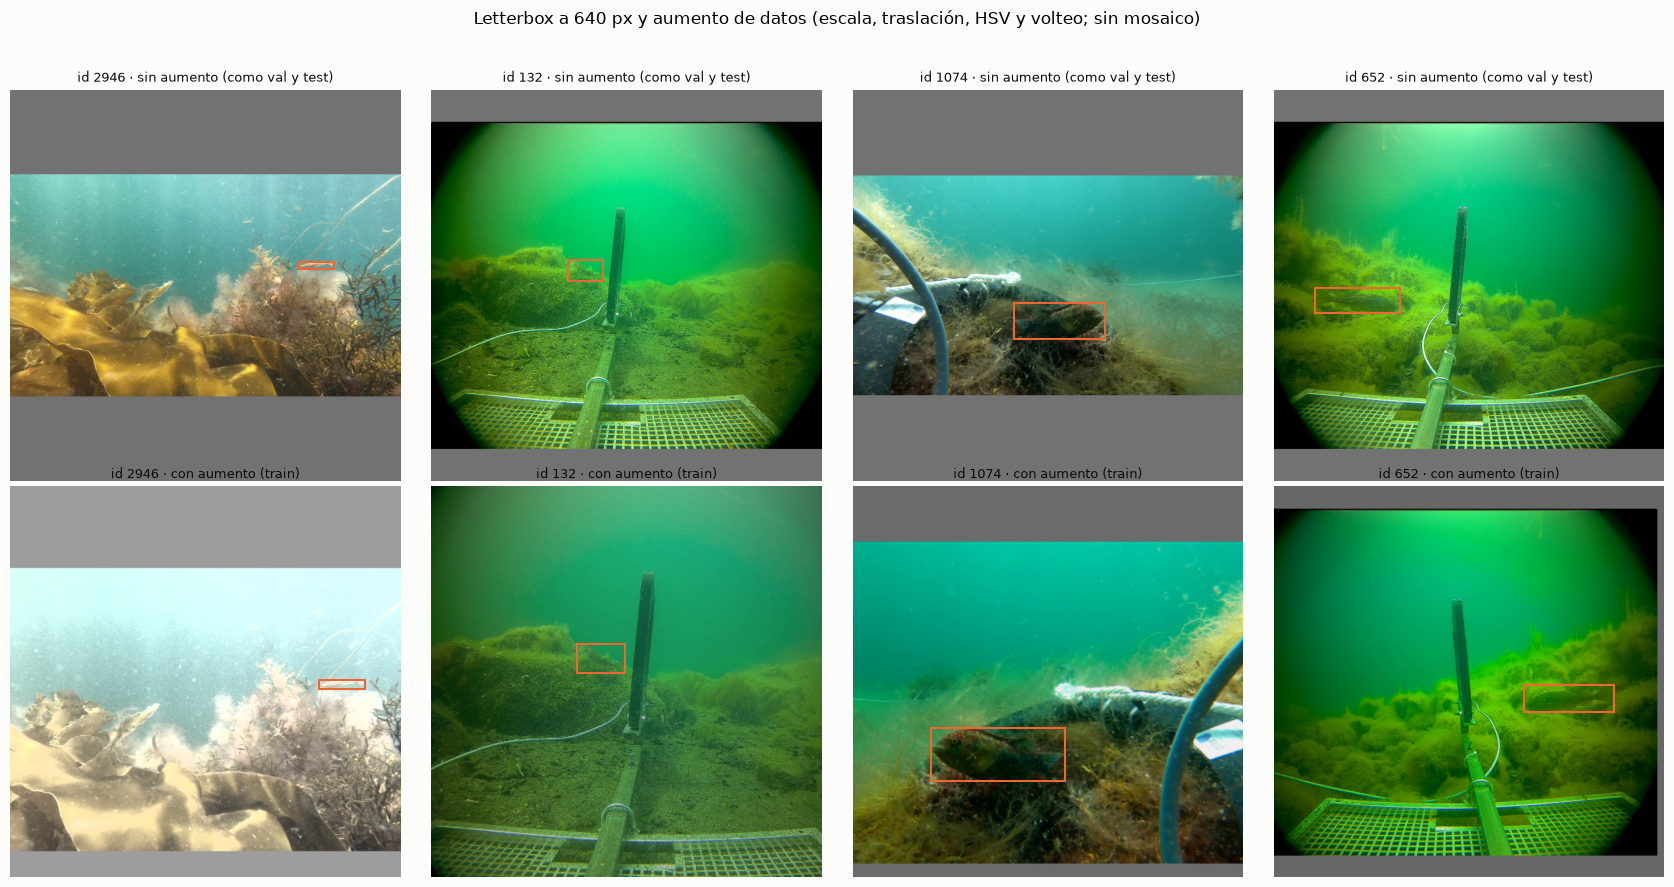

In [10]:
ids_ejemplo = random.Random(SEMILLA).sample(particion["train"], 4)
sin_aumento = DatasetFjordFish("train", ids_ejemplo, aumentar=False)
con_aumento = DatasetFjordFish("train", ids_ejemplo, aumentar=True)
fig, axes = plt.subplots(2, 4, figsize=(17, 9))
for k in range(4):
    imagen, objetivos, letterbox = sin_aumento[k]
    dibujar_lienzo(axes[0, k], imagen, objetivos, f"id {letterbox['id']} · sin aumento (como val y test)")
    imagen, objetivos, letterbox = con_aumento[k]
    dibujar_lienzo(axes[1, k], imagen, objetivos, f"id {letterbox['id']} · con aumento (train)")
fig.suptitle("Letterbox a 640 px y aumento de datos (escala, traslación, HSV y volteo; sin mosaico)", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(DIR_RESULTADOS / "aumento_de_datos.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Arquitectura, pesos COCO y congelamiento (ítem 2.2)

Faster R-CNN es un detector de **dos etapas**:
- **Backbone ResNet-50 con FPN:** extrae características y las combina en varias escalas.
- **RPN (*region proposal network*):** primera etapa; propone regiones que podrían contener un objeto.
- **Cabeza ROI:** segunda etapa; toma cada región propuesta, recorta sus características (`roi_align`) y la pasa por `box_head` y por `box_predictor`, que deciden su clase y ajustan su caja.

El modelo normaliza internamente las imágenes con la media y la desviación de ImageNet, las mismas con que se entrenó el backbone. Con `min_size = max_size = LADO`, el lienzo de 640 × 640 entra sin cambiar de tamaño.

COCO tiene 91 índices de clase y FjordFish 29 (28 clases + fondo), así que se reemplaza `box_predictor` por uno nuevo. Con `box_score_thresh`, `box_nms_thresh` y `box_detections_per_img` se fija el mismo protocolo de detecciones de los otros modelos; Faster R-CNN ya entrega una detección por clase (multietiqueta).

In [11]:
def crear_modelo():
    """Faster R-CNN ResNet50-FPN v2 con pesos COCO y un predictor nuevo para las 28 clases + fondo."""
    red = fasterrcnn_resnet50_fpn_v2(
        weights=FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1, trainable_backbone_layers=CAPAS_ENTRENABLES_BACKBONE,
        min_size=LADO, max_size=LADO,
        box_score_thresh=CONF_EVALUACION, box_nms_thresh=IOU_NMS, box_detections_per_img=MAX_DETECCIONES)
    entradas = red.roi_heads.box_predictor.cls_score.in_features
    red.roi_heads.box_predictor = FastRCNNPredictor(entradas, NUM_CLASES + 1)
    return red


def a_la_gpu(imagenes):
    """Lote de imágenes uint8 → lista de imágenes en la GPU con valores en [0, 1], el formato que recibe el modelo."""
    return list(imagenes.to(DISPOSITIVO, non_blocking=True).float() / 255)

La tabla se calcula sobre el modelo real, no a partir de la configuración:
- **entrenables / congelados:** parámetros que se actualizan durante el entrenamiento y parámetros que quedan fijos. La celda verifica que no hay ninguno congelado: con `CAPAS_ENTRENABLES_BACKBONE = 5` se entrena todo el backbone.
- **desde COCO / nuevos:** parámetros que parten con el valor de los pesos COCO y parámetros que parten con valores aleatorios. `box_predictor` es el único componente nuevo.
- **capas BatchNorm:** cantidad de capas `BatchNorm2d` de cada componente. Durante el entrenamiento se actualizan sus parámetros y sus estadísticas, con lotes de `LOTE` imágenes.
- **Total:** la suma de cada columna.

In [12]:
COMPONENTES = {
    "backbone.body.conv1": "Backbone: conv1 y bn1", "backbone.body.bn1": "Backbone: conv1 y bn1",
    "backbone.body.layer1": "Backbone: layer1", "backbone.body.layer2": "Backbone: layer2",
    "backbone.body.layer3": "Backbone: layer3", "backbone.body.layer4": "Backbone: layer4",
    "backbone.fpn": "FPN", "rpn": "RPN", "roi_heads.box_head": "Cabeza ROI: box_head",
    "roi_heads.box_predictor": "Cabeza ROI: box_predictor",
}


def componente_de(nombre):
    """Componente de Faster R-CNN al que pertenece un parámetro o una capa, según su nombre."""
    return next(etiqueta for prefijo, etiqueta in COMPONENTES.items() if nombre.startswith(prefijo))


def tabla_de_componentes(red, pesos_coco):
    """Por componente: parámetros, cuántos se entrenan, cuántos vienen de COCO y cuántas capas BatchNorm tiene."""
    columnas = ["parámetros", "entrenables", "congelados", "desde COCO", "nuevos", "capas BatchNorm"]
    filas = {etiqueta: dict.fromkeys(columnas, 0) for etiqueta in COMPONENTES.values()}
    for nombre, p in red.named_parameters():
        fila = filas[componente_de(nombre)]
        coco = pesos_coco.get(nombre)
        desde_coco = coco is not None and coco.shape == p.shape and torch.equal(coco.to(p.device), p)
        fila["parámetros"] += p.numel()
        fila["entrenables" if p.requires_grad else "congelados"] += p.numel()
        fila["desde COCO" if desde_coco else "nuevos"] += p.numel()
    for nombre, capa in red.named_modules():
        if isinstance(capa, nn.BatchNorm2d):
            filas[componente_de(nombre)]["capas BatchNorm"] += 1
    return pd.DataFrame(filas).T.rename_axis("componente")


torch.manual_seed(SEMILLA)
modelo_inicial = crear_modelo().to(DISPOSITIVO)
pesos_coco = FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1.get_state_dict(progress=False)
tabla_componentes = tabla_de_componentes(modelo_inicial, pesos_coco)
assert tabla_componentes.congelados.sum() == 0, "Con fine-tuning completo no debería quedar ningún parámetro congelado"
tabla_componentes.loc["Total"] = tabla_componentes.sum()
tabla_componentes.to_csv(DIR_RESULTADOS / "componentes.csv")
tabla_componentes

,parámetros,entrenables,congelados,desde COCO,nuevos,capas BatchNorm
componente,,,,,,
Backbone: conv1 y bn1,9536,9536,0,9536,0,1
Backbone: layer1,215808,215808,0,215808,0,10
Backbone: layer2,1219584,1219584,0,1219584,0,13
Backbone: layer3,7098368,7098368,0,7098368,0,19
Backbone: layer4,14964736,14964736,0,14964736,0,10
FPN,3346432,3346432,0,3346432,0,8
RPN,1184015,1184015,0,1184015,0,0
Cabeza ROI: box_head,15207424,15207424,0,15207424,0,4
Cabeza ROI: box_predictor,148625,148625,0,0,148625,0


torchvision recibe los objetivos como cajas (x1, y1, x2, y2) en píxeles del lienzo y clases desde 1, porque el índice 0 es el fondo. Al detectar, las clases se devuelven restando 1. Esta función hace la conversión.

In [13]:
def objetivos_torchvision(objetivos):
    """Objetivos (clase, cx, cy, w, h normalizados) → lista de diccionarios en el formato de torchvision."""
    salida = []
    for o in objetivos:
        cajas = torch.from_numpy(cxcywh_a_xyxy(o[:, 1:].numpy()) * LADO).float().to(DISPOSITIVO)
        salida.append({"boxes": cajas, "labels": (o[:, 0].long() + 1).to(DISPOSITIVO)})
    return salida

Para verificar las formas y el rango de las clases, se calculan las pérdidas de un lote con la red recién creada. Después se libera esa red: el entrenamiento parte de una red nueva.

In [14]:
cargador = lotes(datos_train, LOTE)
imagenes, objetivos, _ = next(cargador)
cargador.close()                          # solo se necesita el primer lote
assert imagenes.shape == (LOTE, 3, LADO, LADO) and imagenes.dtype == torch.uint8, f"lote inesperado: {imagenes.shape}"
assert all(((o[:, 0] >= 0) & (o[:, 0] < NUM_CLASES)).all() for o in objetivos), "Hay clases fuera de 0..27"
modelo_inicial.train()
with torch.no_grad():
    perdidas_iniciales = modelo_inicial(a_la_gpu(imagenes), objetivos_torchvision(objetivos))
print("Pérdidas de un lote con la red sin entrenar:", {nombre: round(valor.item(), 4) for nombre, valor in perdidas_iniciales.items()})
del modelo_inicial, pesos_coco, perdidas_iniciales
torch.cuda.empty_cache()

Pérdidas de un lote con la red sin entrenar: {'loss_classifier': 3.6529, 'loss_box_reg': 0.2094, 'loss_objectness': 0.634, 'loss_rpn_box_reg': 0.0413}


## 5. Optimizador y ciclo de entrenamiento

- **SGD con momentum**, con tasa de aprendizaje constante (`TASA_APRENDIZAJE`), `MOMENTUM` y `WEIGHT_DECAY` sobre todos los parámetros. Son los valores del tutorial de *fine-tuning* de torchvision; ese tutorial, además, calienta la tasa en la primera época y la reduce por etapas, y aquí se mantiene constante.
- **Precisión mixta:** el `GradScaler` escala la pérdida para que los gradientes en float16 no se vuelvan cero. Puede descartar algunos pasos al comienzo mientras ajusta su escala; se cuentan y se informan.
- **Pérdida de Faster R-CNN:** torchvision entrega cuatro términos, que se suman: clasificación y caja de la cabeza ROI, y objetividad y caja de la RPN.
- **Validación:** torchvision solo calcula pérdidas en modo entrenamiento y solo entrega detecciones en modo evaluación, por eso hay dos pasadas por validación. En la de la pérdida, las capas BatchNorm quedan en modo evaluación para no alterar sus estadísticas.
- **Modo determinista**, igual que los otros modelos. No garantiza resultados idénticos entre corridas: `roi_align` sigue usando su versión normal para GPU, porque la versión determinista de torchvision no está disponible en este entorno, y otras operaciones sin versión determinista solo generan un aviso (oculto en la primera celda). En una medición de 40 pasos de entrenamiento en la RTX 4060, el tiempo fue el mismo con y sin este modo (357 ms por paso).

In [15]:
def crear_optimizador(red):
    """SGD con momentum sobre los parámetros entrenables y el escalador de la precisión mixta."""
    entrenables = [p for p in red.parameters() if p.requires_grad]
    optimizador = torch.optim.SGD(entrenables, lr=TASA_APRENDIZAJE, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
    return optimizador, torch.amp.GradScaler("cuda", enabled=USAR_AMP)


def modo_determinista(activar):
    """Activa o desactiva los algoritmos deterministas de PyTorch, igual que YOLO con deterministic=True."""
    torch.use_deterministic_algorithms(activar, warn_only=True)
    torch.backends.cudnn.deterministic = activar
    torch.utils.deterministic.fill_uninitialized_memory = not activar   # Ultralytics también omite este relleno


def resumir_perdidas(sumas, n_lotes):
    """Promedia por lote los cuatro términos de torchvision y los agrupa en total, clase, caja y RPN."""
    n = max(n_lotes, 1)
    return {"perdida": sum(sumas.values()) / n, "perdida_clase": sumas["loss_classifier"] / n,
            "perdida_caja": sumas["loss_box_reg"] / n,
            "perdida_rpn": (sumas["loss_objectness"] + sumas["loss_rpn_box_reg"]) / n}

Las funciones de una época de entrenamiento y de la pérdida de validación. `entrenar_epoca` omite el último lote si queda incompleto: 1773 imágenes en lotes de 4 dejan 1 sobrando, y por la mezcla esa imagen cambia en cada época. Si la pérdida deja de ser finita, `entrenar_epoca` lanza `PerdidaNoFinita`; la sección 6 la captura, detiene el entrenamiento y conserva los mejores pesos guardados.

In [16]:
class PerdidaNoFinita(Exception):
    """La pérdida dejó de ser finita: el entrenamiento divergió."""


def entrenar_epoca(red, dataset, optimizador, escalador):
    """Una época de entrenamiento; al final avanza `dataset.epoca` para que la siguiente use otro aumento."""
    red.train()
    sumas, n_lotes, descartados = Counter(), 0, 0
    for imagenes, objetivos, _ in lotes(dataset, LOTE, mezclar=True):
        if len(imagenes) < LOTE:                  # se omite el último lote si queda incompleto
            continue
        with torch.autocast(DISPOSITIVO.type, dtype=torch.float16, enabled=USAR_AMP):
            perdidas = red(a_la_gpu(imagenes), objetivos_torchvision(objetivos))
            total = sum(perdidas.values())
        if not math.isfinite(total.item()):
            raise PerdidaNoFinita(f"La pérdida dejó de ser finita en la época {dataset.epoca + 1}: el entrenamiento se detiene")
        escalador.scale(total).backward()
        escala_antes = escalador.get_scale()
        escalador.step(optimizador)
        escalador.update()
        optimizador.zero_grad(set_to_none=True)
        descartados += escalador.get_scale() < escala_antes      # GradScaler baja la escala cuando descarta un paso
        sumas.update({nombre: valor.item() for nombre, valor in perdidas.items()})
        n_lotes += 1
    dataset.epoca += 1
    return {**resumir_perdidas(sumas, n_lotes), "pasos_descartados": descartados}


@torch.no_grad()
def perdida_validacion(red, dataset):
    """Pérdida en un dataset sin aumento: modo entrenamiento, pero con BatchNorm en modo evaluación."""
    red.train()
    for capa in red.modules():
        if isinstance(capa, nn.BatchNorm2d):
            capa.eval()
    sumas, n_lotes = Counter(), 0
    for imagenes, objetivos, _ in lotes(dataset, LOTE_EVALUACION):
        with torch.autocast(DISPOSITIVO.type, dtype=torch.float16, enabled=USAR_AMP):
            perdidas = red(a_la_gpu(imagenes), objetivos_torchvision(objetivos))
        sumas.update({nombre: valor.item() for nombre, valor in perdidas.items()})
        n_lotes += 1
    return resumir_perdidas(sumas, n_lotes)

`predecir` entrega las detecciones de la red en un dataset sin aumento; se usa en la validación de cada época y en la evaluación final. `a_filas` las pasa al formato común y deshace el letterbox, para dejar las cajas en píxeles de la imagen de `datasets/fjordfish/`.

In [17]:
def a_filas(detecciones, lista_letterbox):
    """Detecciones en px del lienzo → filas del formato común, en px de la imagen de datasets/fjordfish."""
    filas = []
    for (xyxy, conf, cls), letterbox in zip(detecciones, lista_letterbox):
        xyxy = xyxy.cpu().numpy()
        x = ((xyxy[:, [0, 2]] - letterbox["dx"]) * letterbox["factor_x"]).clip(0, letterbox["ancho"])   # se deshace el letterbox
        y = ((xyxy[:, [1, 3]] - letterbox["dy"]) * letterbox["factor_y"]).clip(0, letterbox["alto"])
        for c, p, (x1, x2), (y1, y2) in zip(cls.tolist(), conf.tolist(), x.tolist(), y.tolist()):
            filas.append((letterbox["id"], c, round(p, 5), round(x1, 1), round(y1, 1), round(x2, 1), round(y2, 1)))
    return filas


@torch.no_grad()
def predecir(red, dataset, precision_mixta=False):
    """Detecciones de la red en un dataset sin aumento, en el formato común (por defecto en float32, como YOLO al evaluar)."""
    red.eval()
    filas = []
    for imagenes, _, lista_letterbox in lotes(dataset, LOTE_EVALUACION):
        with torch.autocast(DISPOSITIVO.type, dtype=torch.float16, enabled=precision_mixta and USAR_AMP):
            salidas = red(a_la_gpu(imagenes))
        detecciones = [(s["boxes"], s["scores"], s["labels"] - 1) for s in salidas]     # torchvision: 0 es el fondo
        filas += a_filas(detecciones, lista_letterbox)
    return pd.DataFrame(filas, columns=COLUMNAS_PREDICCIONES)

## 6. Entrenamiento

Se entrena durante hasta `EPOCAS` épocas. Después de cada época se calculan la pérdida y el mAP de validación (con el evaluador común y en float16, como YOLO al entrenar), y se guardan los pesos de la época con mayor mAP50-95; si no mejora en `PACIENCIA` épocas, el entrenamiento se detiene. Test no se usa en esta sección.

El tiempo de cada época incluye toda la validación. Aquí son dos pasadas (sección 5) y en YOLO es una sola; por eso `historial_completo.csv` guarda aparte `segundos_perdida_val`, la duración de la pasada que calcula la pérdida.

En `~/tarea2_runs/reales/faster_rcnn/` (fuera de OneDrive) quedan:
- `mejor.pt`: pesos de la mejor época.
- `historial_completo.csv`: métricas por época. Se actualiza en cada época y permite seguir el avance.
- `info_entrenamiento.json`: estado del entrenamiento, configuración, tiempo total y memoria de la GPU.

Estas funciones evitan perder un entrenamiento largo por un fallo:
- Si se lanza de nuevo con `ENTRENAR = True`, los archivos del entrenamiento anterior se mueven a una carpeta `anterior_<fecha>`, sin borrarlos.
- Si el entrenamiento se corta, `mejor.pt` y el historial se conservan, y `info_entrenamiento.json` indica el `estado`: `en curso` (se cortó el proceso), `interrumpido` (ocurrió un error) o `divergió` (la pérdida dejó de ser finita). Con `ENTRENAR = False`, el cuaderno sigue con los mejores pesos guardados y avisa que el entrenamiento no terminó.

In [18]:
PESOS = DIR_RUNS / "mejor.pt"
HISTORIAL = DIR_RUNS / "historial_completo.csv"
INFO = DIR_RUNS / "info_entrenamiento.json"


def archivar_entrenamiento_anterior():
    """Mueve los archivos de un entrenamiento anterior a una carpeta con fecha: no se cargan por error ni se pierden."""
    anteriores = [archivo for archivo in (PESOS, HISTORIAL, INFO) if archivo.exists()]
    if anteriores:
        destino = DIR_RUNS / f"anterior_{time.strftime('%Y%m%d_%H%M%S')}"
        destino.mkdir()
        for archivo in anteriores:
            archivo.replace(destino / archivo.name)
        print("Entrenamiento anterior movido a", destino)


def guardar_historial(filas):
    """Escribe el historial; si el archivo está abierto en otro programa, avisa y sigue: la próxima escritura lo deja completo."""
    try:
        pd.DataFrame(filas).to_csv(HISTORIAL, index=False)
    except PermissionError:
        print(f"  Aviso: {HISTORIAL.name} está abierto en otro programa y no se pudo actualizar")


def guardar_info(estado, mejor_epoca, segundos):
    """Escribe cómo va o cómo terminó el entrenamiento, junto con su configuración."""
    info = {
        "modelo": "Faster R-CNN ResNet50-FPN v2 (COCO)", "estado": estado, "tiempo_entrenamiento_s": round(segundos, 1),
        "memoria_gpu_max_GB": round(torch.cuda.max_memory_reserved() / 1e9, 2) if torch.cuda.is_available() else None,
        "dispositivo": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
        "mejor_epoca": mejor_epoca,
        "configuracion": {
            "capas_entrenables_backbone": CAPAS_ENTRENABLES_BACKBONE, "lado": LADO, "epocas": EPOCAS, "paciencia": PACIENCIA,
            "lote": LOTE, "tasa_aprendizaje": TASA_APRENDIZAJE, "momentum": MOMENTUM, "weight_decay": WEIGHT_DECAY,
            "precision_mixta": USAR_AMP},
        "aumento_datos": {"escala": ESCALA, "traslacion": TRASLACION, "hsv": [HSV_H, HSV_S, HSV_V], "volteo": VOLTEO, "mosaico": 0.0},
        "fraccion_train": FRACCION_TRAIN, "semilla": SEMILLA, "huella_particion": huella,
    }
    INFO.write_text(json.dumps(info, indent=2, ensure_ascii=False), encoding="utf-8")

El ciclo de entrenamiento. Con `ENTRENAR = False` esta celda solo carga las cajas reales de validación.

In [19]:
reales_val = cargar_cajas_reales(DIR_DATASET, "val", particion["val"])

if ENTRENAR:
    archivar_entrenamiento_anterior()
    random.seed(SEMILLA)
    torch.manual_seed(SEMILLA)
    datos_train.epoca = 0                         # así, repetir solo esta celda da lo mismo que Restart & Run All
    modelo = crear_modelo().to(DISPOSITIVO)
    optimizador, escalador = crear_optimizador(modelo)
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    modo_determinista(True)                       # como YOLO (deterministic=True)
    filas_historial, mejor_map, mejor_epoca, sin_mejora = [], -1.0, 0, 0
    estado = "interrumpido"                       # queda así si ocurre un error
    t_inicio = time.perf_counter()
    try:
        for epoca in range(1, EPOCAS + 1):
            perdidas_train = entrenar_epoca(modelo, datos_train, optimizador, escalador)
            t_perdida_val = time.perf_counter()
            with torch.random.fork_rng():         # esta pasada sortea regiones: así no altera los sorteos del entrenamiento
                perdidas_val = perdida_validacion(modelo, datos_val)
            segundos_perdida_val = time.perf_counter() - t_perdida_val
            metricas_val = evaluar_detecciones(predecir(modelo, datos_val, precision_mixta=True), reales_val)
            filas_historial.append({
                "epoca": epoca, "tiempo_s": time.perf_counter() - t_inicio,
                "perdida_train": perdidas_train["perdida"], "perdida_val": perdidas_val["perdida"],
                "val_mAP50": metricas_val["mAP50"], "val_mAP50_95": metricas_val["mAP50_95"],
                "perdida_clase_train": perdidas_train["perdida_clase"], "perdida_clase_val": perdidas_val["perdida_clase"],
                "perdida_caja_train": perdidas_train["perdida_caja"], "perdida_caja_val": perdidas_val["perdida_caja"],
                "perdida_rpn_train": perdidas_train["perdida_rpn"], "perdida_rpn_val": perdidas_val["perdida_rpn"],
                "pasos_descartados": perdidas_train["pasos_descartados"], "segundos_perdida_val": segundos_perdida_val})
            if metricas_val["mAP50_95"] > mejor_map:
                mejor_map, mejor_epoca, sin_mejora = metricas_val["mAP50_95"], epoca, 0
                torch.save(modelo.state_dict(), PESOS)
            else:
                sin_mejora += 1
            guardar_historial(filas_historial)
            guardar_info("en curso", mejor_epoca, time.perf_counter() - t_inicio)
            fila = filas_historial[-1]
            print(f"época {epoca:3d} | pérdida train {fila['perdida_train']:.4f} · val {fila['perdida_val']:.4f} | "
                  f"val mAP50 {fila['val_mAP50']:.3f} · mAP50-95 {fila['val_mAP50_95']:.3f} | {fila['tiempo_s'] / 60:5.1f} min")
            if epoca == 1:
                print(f"  ≈ {fila['tiempo_s'] / 60:.1f} min por época → {EPOCAS} épocas ≈ {fila['tiempo_s'] * EPOCAS / 3600:.1f} h como máximo")
            if sin_mejora >= PACIENCIA:
                print(f"Parada temprana: {PACIENCIA} épocas sin mejorar el mAP50-95 de validación (mejor época: {mejor_epoca})")
                break
        estado = "completo"
    except PerdidaNoFinita as error:
        estado = "divergió"
        print(error)
    finally:
        modo_determinista(False)
        guardar_historial(filas_historial)
        guardar_info(estado, mejor_epoca, time.perf_counter() - t_inicio)
    del modelo, optimizador, escalador            # libera la GPU: así la medición de velocidad no depende de ENTRENAR
    gc.collect()
    torch.cuda.empty_cache()

época   1 | pérdida train 0.4179 · val 0.3112 | val mAP50 0.142 · mAP50-95 0.080 |   3.2 min
  ≈ 3.2 min por época → 100 épocas ≈ 5.3 h como máximo


época   2 | pérdida train 0.2846 · val 0.2523 | val mAP50 0.193 · mAP50-95 0.118 |   6.3 min


época   3 | pérdida train 0.2588 · val 0.2590 | val mAP50 0.204 · mAP50-95 0.122 |   9.5 min


época   4 | pérdida train 0.2453 · val 0.2343 | val mAP50 0.238 · mAP50-95 0.146 |  12.6 min


época   5 | pérdida train 0.2306 · val 0.2351 | val mAP50 0.218 · mAP50-95 0.138 |  15.8 min


época   6 | pérdida train 0.2267 · val 0.2281 | val mAP50 0.258 · mAP50-95 0.159 |  18.9 min


... (42 outputs left out)

época  49 | pérdida train 0.1536 · val 0.2591 | val mAP50 0.312 · mAP50-95 0.205 | 154.4 min


época  50 | pérdida train 0.1610 · val 0.2361 | val mAP50 0.336 · mAP50-95 0.226 | 157.5 min


época  51 | pérdida train 0.1540 · val 0.2251 | val mAP50 0.341 · mAP50-95 0.232 | 160.7 min


época  52 | pérdida train 0.1601 · val 0.2201 | val mAP50 0.329 · mAP50-95 0.216 | 163.8 min
Parada temprana: 25 épocas sin mejorar el mAP50-95 de validación (mejor época: 27)


Se carga la mejor época, que es la que se evalúa desde aquí en adelante. Con `ENTRENAR = False` se leen el historial y la información guardados.

In [20]:
info_entrenamiento = json.loads(INFO.read_text(encoding="utf-8"))
mejor_epoca = info_entrenamiento["mejor_epoca"]
assert mejor_epoca >= 1, "El entrenamiento no alcanzó a guardar pesos"
if info_entrenamiento["estado"] != "completo":
    print(f"Aviso: el entrenamiento no terminó (estado: {info_entrenamiento['estado']}); se usa su mejor época guardada")
historial = pd.read_csv(HISTORIAL)
modelo = crear_modelo().to(DISPOSITIVO)
modelo.load_state_dict(torch.load(PESOS, map_location=DISPOSITIVO))
modelo.eval()
tiempo_por_epoca_s = float(historial.tiempo_s.iloc[-1] / len(historial))
print(f"Tiempo total de entrenamiento: {info_entrenamiento['tiempo_entrenamiento_s'] / 60:.1f} min | "
      f"épocas: {len(historial)} | mejor época: {mejor_epoca} | tiempo medio por época: {tiempo_por_epoca_s:.1f} s")

Tiempo total de entrenamiento: 163.8 min | épocas: 52 | mejor época: 27 | tiempo medio por época: 189.0 s


## 7. Curvas de entrenamiento

Pérdidas de entrenamiento y validación por época (total, de clase, de caja y de la RPN, promediadas por lote) y mAP de validación. La línea discontinua marca la mejor época.

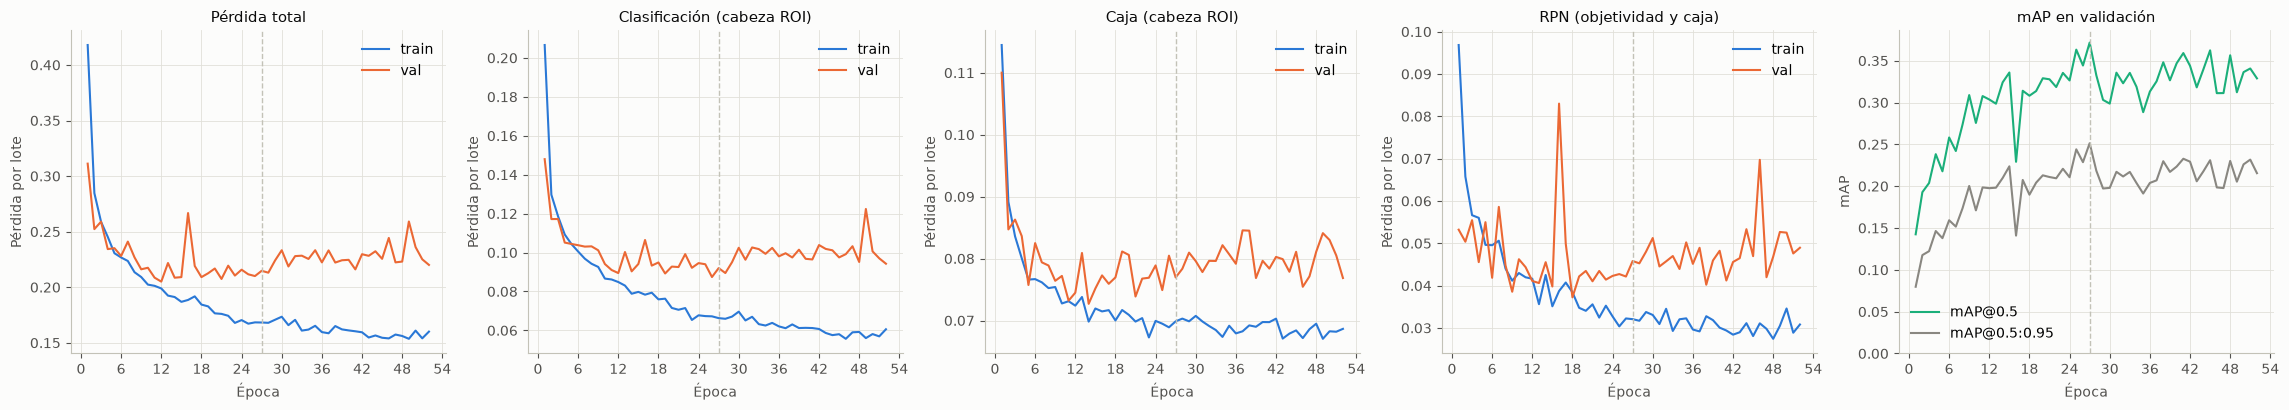

In [21]:
fig, axes = plt.subplots(1, 5, figsize=(23, 4.2))
for ax, (base, titulo) in zip(axes, [("perdida", "Pérdida total"), ("perdida_clase", "Clasificación (cabeza ROI)"),
                                     ("perdida_caja", "Caja (cabeza ROI)"), ("perdida_rpn", "RPN (objetividad y caja)")]):
    ax.plot(historial.epoca, historial[f"{base}_train"], color=AZUL, lw=1.5, label="train")
    ax.plot(historial.epoca, historial[f"{base}_val"], color=NARANJA, lw=1.5, label="val")
    ax.set_title(titulo)
    ax.set_ylabel("Pérdida por lote")
    ax.legend()
axes[4].plot(historial.epoca, historial.val_mAP50, color=AQUA, lw=1.5, label="mAP@0.5")
axes[4].plot(historial.epoca, historial.val_mAP50_95, color=GRIS, lw=1.5, label="mAP@0.5:0.95")
axes[4].set_title("mAP en validación")
axes[4].set_ylabel("mAP")
axes[4].set_ylim(0, None)
axes[4].legend()
for ax in axes:
    ax.set_xlabel("Época")
    ax.axvline(mejor_epoca, color="#c3c2b7", ls="--", lw=1)
    epocas_enteras(ax)
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "curvas_entrenamiento.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Evaluación en validación y test (evaluador común)

Se evalúa la mejor época en validación y, una sola vez, en test, en float32 (como `val` de Ultralytics) y con el evaluador común de `comun.py`, el mismo que se usa para los cuatro modelos:
- **mAP50, mAP75 y mAP50-95** (definición COCO), promediando las clases con instancias en el conjunto evaluado;
- **precisión, recall y F1** con IoU 0,5 y confianza ≥ `UMBRAL_CONFIANZA`, promediados entre clases. El umbral es provisorio: `05_comparacion.ipynb` los recalcula con el umbral común que elija el grupo (D8).

In [22]:
CLAVES_METRICAS = ("precision", "recall", "F1", "mAP50", "mAP75", "mAP50_95")
predicciones, metricas = {}, {}
for split, dataset in (("val", datos_val), ("test", datos_test)):
    predicciones[split] = predecir(modelo, dataset)
    reales = cargar_cajas_reales(DIR_DATASET, split, particion[split])
    metricas[split] = evaluar_detecciones(predicciones[split], reales, nombres=NOMBRES, umbral_confianza=UMBRAL_CONFIANZA)
    print(f"{split}: {len(predicciones[split])} detecciones en {predicciones[split].id.nunique()} imágenes")

tabla_global = pd.DataFrame({s: {k: m[k] for k in CLAVES_METRICAS} for s, m in metricas.items()}).T.rename_axis("partición")
tabla_global.to_csv(DIR_RESULTADOS / "metricas_val_test.csv")
tabla_global.round(4)

val: 62302 detecciones en 313 imágenes


test: 184442 detecciones en 916 imágenes


,precision,recall,F1,mAP50,mAP75,mAP50_95
partición,,,,,,
val,0.2115,0.4009,0.2769,0.3701,0.2739,0.2511
test,0.2153,0.3936,0.2783,0.3527,0.2519,0.2254


AP por clase en test (solo aparecen las clases con instancias en test).

In [23]:
por_clase = metricas["test"]["por_clase"]
por_clase.to_csv(DIR_RESULTADOS / "metricas_por_clase_test.csv", index=False)
por_clase.sort_values("instancias", ascending=False).reset_index(drop=True).round(4)

,clase_id,clase,instancias,predicciones,AP50,AP75,AP50_95
0,5,goldsinny,474,47158,0.6353,0.4087,0.3706
1,4,corkwing_male,385,11062,0.8854,0.6619,0.6029
2,8,cod,201,12238,0.8334,0.6533,0.5680
3,16,spiny_dogfish,175,5112,0.7932,0.5617,0.4935
4,7,labrids_unknown,139,8386,0.1382,0.0761,0.0754
5,3,corkwing_female,136,9521,0.6064,0.4530,0.4016
6,18,brown_crab,76,14486,0.5122,0.1361,0.2226
7,15,gadines_unknown,63,8495,0.0969,0.0408,0.0480
8,9,cod_yoy,51,11107,0.4808,0.2509,0.2509
9,6,rock_cook,50,4180,0.6114,0.5893,0.4653


El mismo AP50 por clase como gráfico, de menor a mayor, con el número de instancias de cada clase en test.

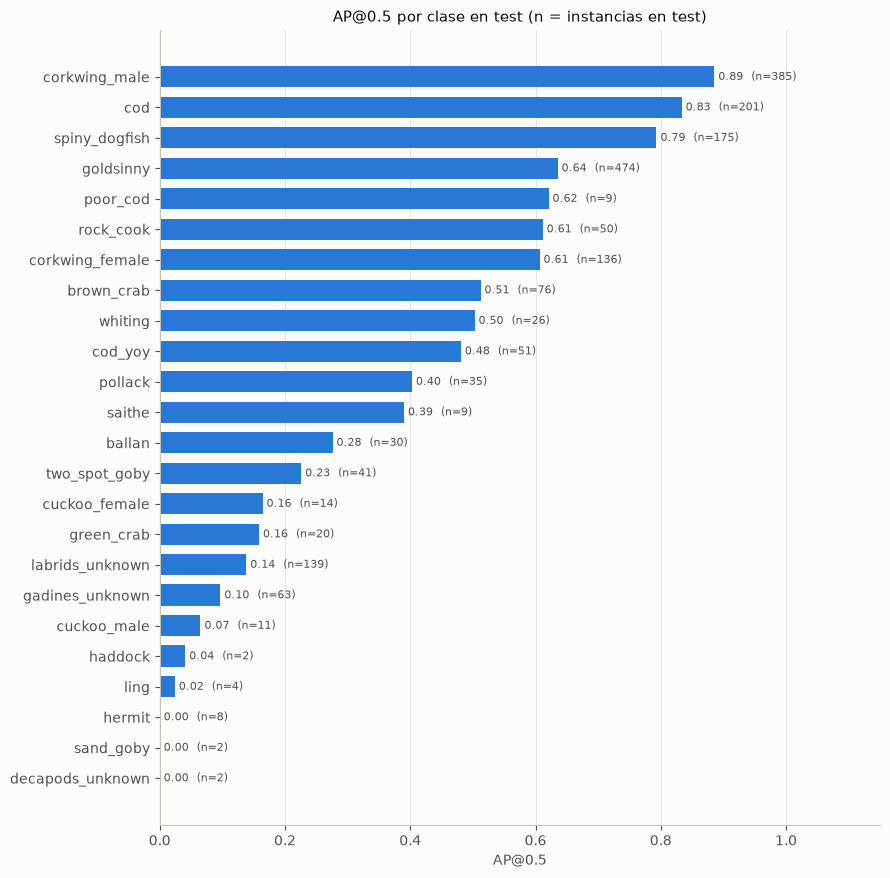

In [24]:
barras = por_clase.sort_values(["AP50", "instancias"])
fig, ax = plt.subplots(figsize=(9, 0.32 * len(barras) + 1.2))
ax.barh(barras.clase, barras.AP50, height=0.7, color=AZUL)
for yi, (v, n) in enumerate(zip(barras.AP50, barras.instancias)):
    ax.text(v, yi, f" {v:.2f}  (n={n})", va="center", fontsize=8, color="#52514e")
ax.set_xlim(0, 1.15)
ax.set_xlabel("AP@0.5")
ax.set_title("AP@0.5 por clase en test (n = instancias en test)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "ap50_por_clase_test.png", dpi=150, bbox_inches="tight")
plt.show()

Curva precisión-recall en test con IoU 0,5: la precisión media entre clases para cada nivel de recall. El área bajo la curva es el mAP50.

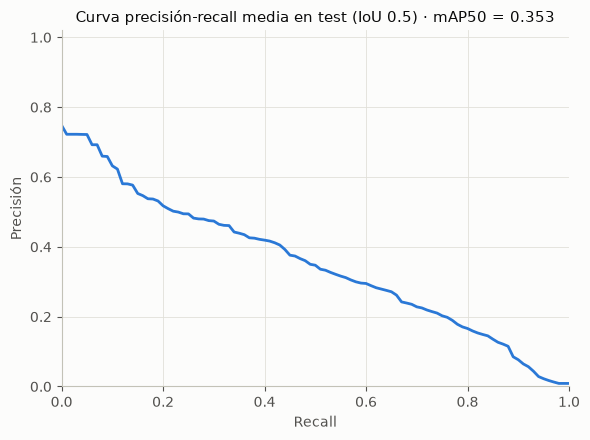

In [25]:
curva = metricas["test"]["curva_pr"]
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(curva.recall, curva.precision, color=AZUL, lw=2)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Recall")
ax.set_ylabel("Precisión")
ax.set_title(f"Curva precisión-recall media en test (IoU 0.5) · mAP50 = {metricas['test']['mAP50']:.3f}")
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "curva_pr_test.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Eficiencia: tamaño del modelo y velocidad de inferencia

Se miden los parámetros, los GFLOPs, el tamaño del archivo de pesos y la velocidad con **lote de 1 imagen** sobre imágenes de test, después de un calentamiento y en float32. Para que sea comparable con `predict` de YOLO, durante esta medición solo se conservan las detecciones con confianza ≥ `UMBRAL_CONFIANZA`.

El tiempo se separa en preproceso (letterbox y paso a la GPU), inferencia (red, incluidas las dos etapas) y postproceso (`postprocess_detections`: filtro por confianza y NMS). Aparte se mide el tiempo de inferencia por imagen con lotes de `LOTE_VELOCIDAD` imágenes (`ms_inferencia_en_lote`). Son 8 imágenes y no 16, como en los otros modelos, porque con 16 se desborda la memoria de la RTX 4060 (8 GB).

Queda una diferencia con YOLO: Ultralytics hace la inferencia con un letterbox rectangular (por ejemplo, 640 × 384 para imágenes 16:9), mientras que aquí el modelo recibe el lienzo de 640 × 640.

In [26]:
def sincronizar():
    """Espera a que la GPU termine, para medir tiempos reales."""
    if DISPOSITIVO.type == "cuda":
        torch.cuda.synchronize()


segundos_postproceso = []
postprocesar_original = modelo.roi_heads.postprocess_detections


def postprocesar_con_tiempo(*args):
    """Llama al postproceso de torchvision y guarda cuánto tardó."""
    sincronizar()
    t = time.perf_counter()
    resultado = postprocesar_original(*args)
    sincronizar()
    segundos_postproceso.append(time.perf_counter() - t)
    return resultado


@torch.no_grad()
def medir_tiempos(ruta):
    """Milisegundos de preproceso, inferencia y postproceso de una imagen con lote 1 (ya leída de disco), en float32."""
    original = cv2.imread(str(ruta))
    sincronizar()
    t0 = time.perf_counter()
    lienzo, *_ = ubicar_en_lienzo(redimensionar(original), np.zeros((0, 4)))
    imagen = torch.from_numpy(np.ascontiguousarray(lienzo[..., ::-1].transpose(2, 0, 1))).to(DISPOSITIVO).float() / 255
    sincronizar()
    t1 = time.perf_counter()
    modelo([imagen])
    sincronizar()
    t2 = time.perf_counter()
    postproceso = segundos_postproceso[-1]
    # Mismas claves que `speed` de Ultralytics
    return {"preprocess": (t1 - t0) * 1000, "inference": (t2 - t1 - postproceso) * 1000, "postprocess": postproceso * 1000}


def fraccion_memoria_gpu():
    """Fracción de la memoria de la GPU que estuvo reservada como máximo desde el último reinicio del contador."""
    if DISPOSITIVO.type != "cuda":
        return 0.0
    return torch.cuda.max_memory_reserved() / torch.cuda.get_device_properties(0).total_memory

La medición con lote 1. Durante las dos mediciones, el modelo usa `UMBRAL_CONFIANZA` y el postproceso cronometrado.

In [27]:
modelo.roi_heads.postprocess_detections = postprocesar_con_tiempo
modelo.roi_heads.score_thresh = UMBRAL_CONFIANZA
for ruta in rutas_test[:N_CALENTAMIENTO]:
    medir_tiempos(ruta)
tiempos = pd.DataFrame([medir_tiempos(ruta) for ruta in rutas_test[:N_IMAGENES_VELOCIDAD]])
ms_total = float(tiempos.sum(axis=1).mean())
print(f"Lote 1: {ms_total:.1f} ms por imagen ({1000 / ms_total:.1f} FPS)")

Lote 1: 67.3 ms por imagen (14.9 FPS)


La medición con lotes de `LOTE_VELOCIDAD` imágenes reales de test. Si la GPU se queda sin memoria no hay error: el tiempo simplemente sube mucho. Por eso la celda avisa si la memoria reservada supera el 90 % del total o si el tiempo por imagen en lote supera al de lote 1. Al terminar, el modelo vuelve a su umbral y a su postproceso originales.

In [28]:
torch.cuda.empty_cache()
if DISPOSITIVO.type == "cuda":
    torch.cuda.reset_peak_memory_stats()
cargador = lotes(datos_test, LOTE_VELOCIDAD)
lotes_velocidad = [a_la_gpu(next(cargador)[0]) for _ in range(N_LOTES_VELOCIDAD)]
cargador.close()
segundos_red = 0.0
with torch.no_grad():
    modelo(lotes_velocidad[0])                   # calentamiento
    for lote_imagenes in lotes_velocidad:
        sincronizar()
        t0 = time.perf_counter()
        modelo(lote_imagenes)
        sincronizar()
        segundos_red += time.perf_counter() - t0 - segundos_postproceso[-1]
ms_inferencia_en_lote = segundos_red * 1000 / (N_LOTES_VELOCIDAD * LOTE_VELOCIDAD)
modelo.roi_heads.postprocess_detections = postprocesar_original
modelo.roi_heads.score_thresh = CONF_EVALUACION
del lotes_velocidad
torch.cuda.empty_cache()
print(f"Lotes de {LOTE_VELOCIDAD}: {ms_inferencia_en_lote:.1f} ms de inferencia por imagen | "
      f"memoria reservada máxima: {fraccion_memoria_gpu():.0%} del total")
if fraccion_memoria_gpu() > 0.9 or ms_inferencia_en_lote > tiempos.inference.mean():
    print("Aviso: la memoria de la GPU pudo desbordarse y este tiempo puede estar inflado")

Lotes de 8: 58.8 ms de inferencia por imagen | memoria reservada máxima: 54% del total


La tabla reúne las mediciones, junto con los parámetros, los GFLOPs y el tamaño del archivo de pesos.
- **Parámetros y GFLOPs:** se cuentan en una pasada con una imagen real de test (2 FLOPs por multiplicación-suma, la misma convención de los otros modelos). Los GFLOPs de Faster R-CNN dependen de cuántas regiones propone la RPN para esa imagen, por eso se miden con la red ya entrenada.
- **Tamaño de los pesos:** este archivo guarda los pesos en float32. Ultralytics guarda los de YOLO en float16, así que esta columna no se compara directamente con YOLO.

In [29]:
def tamano_de_la_red(red):
    """Parámetros y GFLOPs de una pasada con la primera imagen de test."""
    red.eval()
    imagen = a_la_gpu(datos_test[0][0][None])
    with torch.no_grad(), FlopCounterMode(display=False) as contador:
        red(imagen)
    return sum(p.numel() for p in red.parameters()), contador.get_total_flops() / 1e9


n_parametros, gflops = tamano_de_la_red(modelo)
eficiencia = {
    "parametros_M": n_parametros / 1e6,
    "GFLOPs": gflops,
    "tamano_pesos_MB": PESOS.stat().st_size / 1e6,
    "ms_preproceso": float(tiempos.preprocess.mean()),
    "ms_inferencia": float(tiempos.inference.mean()),
    "ms_postproceso": float(tiempos.postprocess.mean()),
    "ms_total_por_imagen": ms_total,
    "FPS": 1000 / ms_total,
    "ms_inferencia_en_lote": ms_inferencia_en_lote,
}
pd.Series(eficiencia).round(3).to_frame("valor")

,valor
parametros_M,43.395
GFLOPs,451.040
tamano_pesos_MB,173.935
ms_preproceso,3.328
ms_inferencia,61.260
ms_postproceso,2.738
ms_total_por_imagen,67.326
FPS,14.853
ms_inferencia_en_lote,58.760


## 10. Resultados cualitativos

Las mismas imágenes de test que muestran los otros cuadernos (misma semilla): anotación real a la izquierda y predicción a la derecha (confianza ≥ `UMBRAL_CONFIANZA`).

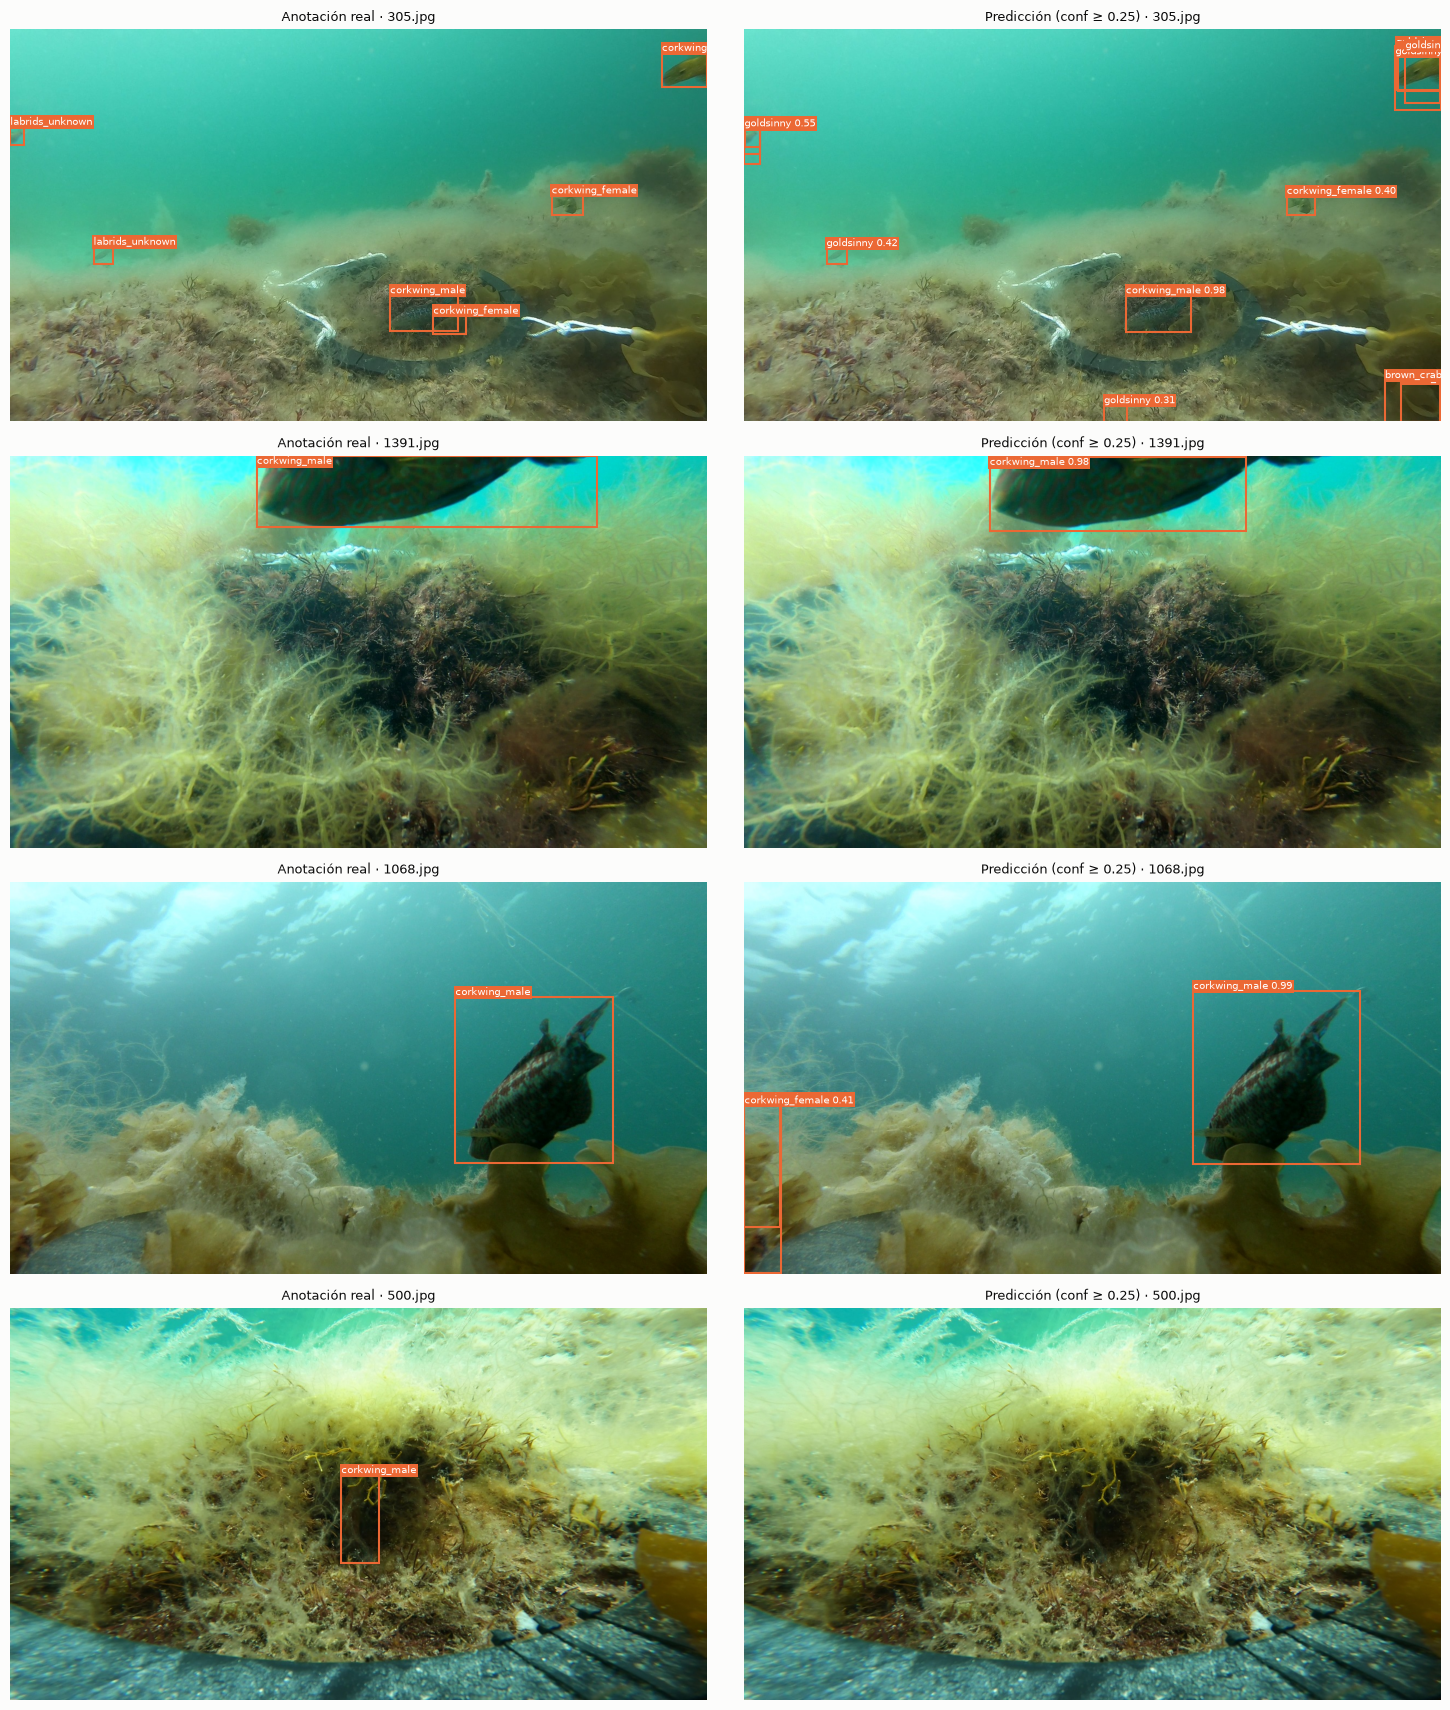

In [30]:
ejemplos = random.Random(SEMILLA).sample(rutas_test, N_EJEMPLOS)
reales_test = cargar_cajas_reales(DIR_DATASET, "test", particion["test"])
pred_test = predicciones["test"]
fig, axes = plt.subplots(N_EJEMPLOS, 2, figsize=(15, 4.3 * N_EJEMPLOS))
for (ax_real, ax_pred), ruta in zip(axes, ejemplos):
    img = Image.open(ruta)
    dibujar_cajas(ax_real, img, reales_test[reales_test.id == ruta.stem], f"Anotación real · {ruta.name}")
    dibujar_cajas(ax_pred, img, pred_test[(pred_test.id == ruta.stem) & (pred_test.confianza >= UMBRAL_CONFIANZA)],
                  f"Predicción (conf ≥ {UMBRAL_CONFIANZA}) · {ruta.name}")
fig.tight_layout()
fig.savefig(DIR_RESULTADOS / "ejemplos_test.png", dpi=120, bbox_inches="tight")
plt.show()

## 11. Predicciones y resumen para la comparación

Se guardan en `resultados/faster_rcnn/` con el formato común: `predicciones_val.csv` y `predicciones_test.csv`, `historial.csv` (columnas comunes por época) y `resumen.json` / `resumen.csv`, con las mismas claves que los otros modelos más los parámetros congelados y entrenables. En este resumen, la precisión, el recall y el F1 usan el umbral provisorio `UMBRAL_CONFIANZA`; `05_comparacion.ipynb` los recalcula para todos los modelos con el umbral común (D8).

In [31]:
for split in ("val", "test"):
    predicciones[split].to_csv(DIR_RESULTADOS / f"predicciones_{split}.csv", index=False)
COLUMNAS_HISTORIAL = ["epoca", "tiempo_s", "perdida_train", "perdida_val", "val_mAP50", "val_mAP50_95"]
historial[COLUMNAS_HISTORIAL].to_csv(DIR_RESULTADOS / "historial.csv", index=False)

resumen = {
    "modelo": "Faster R-CNN preentrenado (ResNet50-FPN v2, COCO)",
    "huella_particion": huella,
    "epocas_ejecutadas": int(historial.epoca.max()),
    "mejor_epoca": mejor_epoca,
    "tiempo_entrenamiento_min": info_entrenamiento["tiempo_entrenamiento_s"] / 60,
    "tiempo_por_epoca_s": tiempo_por_epoca_s,
    "memoria_gpu_max_GB": info_entrenamiento["memoria_gpu_max_GB"],
    **{f"test_{k}": metricas["test"][k] for k in CLAVES_METRICAS},
    **{f"val_{k}": metricas["val"][k] for k in CLAVES_METRICAS},
    **eficiencia,
    "parametros_entrenables_M": tabla_componentes.loc["Total", "entrenables"] / 1e6,
    "parametros_congelados_M": tabla_componentes.loc["Total", "congelados"] / 1e6,
}
(DIR_RESULTADOS / "resumen.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False), encoding="utf-8")
pd.Series(resumen).to_frame("valor").to_csv(DIR_RESULTADOS / "resumen.csv")
pd.Series(resumen).to_frame("valor")

,valor
modelo,"Faster R-CNN preentrenado (ResNet50-FPN v2, COCO)"
huella_particion,7d4e588f7cc4
epocas_ejecutadas,52
mejor_epoca,27
tiempo_entrenamiento_min,163.808333
tiempo_por_epoca_s,189.009422
memoria_gpu_max_GB,3.66
test_precision,0.215275
test_recall,0.393612
test_F1,0.278327


## 12. ✍️ Justificación de las decisiones (completar por el grupo)

> La tarea pide justificar estas decisiones con argumentos propios del grupo; el uso de IA generativa para diseñar la solución o analizar resultados está prohibido.

- **Qué se congeló, qué se entrenó y por qué *fine-tuning* completo**:
- **Elección de ResNet50-FPN v2 y entrada de 640 px**:
- **Optimizador, tasa de aprendizaje y tamaño de lote**:
- **Número de épocas y parada temprana**:
- **Aumento de datos**:

## 13. ✍️ Análisis de resultados (completar por el grupo)

-

## ✍️ Declaración de uso de IA generativa

> Completar según lo que pide la tarea (herramienta y propósito específico).